In [26]:
import numpy as np
import matplotlib.pyplot as plt
import cv2
from PIL import Image

In [27]:
img = cv2.imread("img.jpg",cv2.IMREAD_GRAYSCALE)

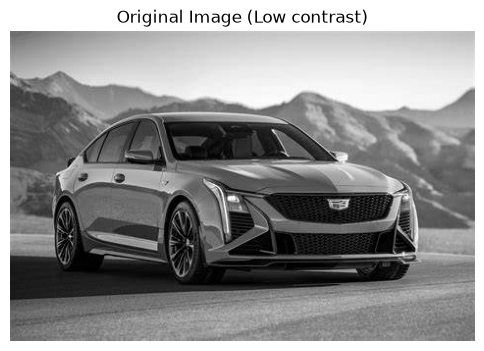

In [28]:
plt.figure(figsize=(6,5))
plt.imshow(img, cmap="gray")
plt.title("Original Image (Low contrast)")
plt.axis("off")
plt.show()

In [29]:
histogram, bin_edges = np.histogram(img.flatten(), bins=256, range=(0,256))

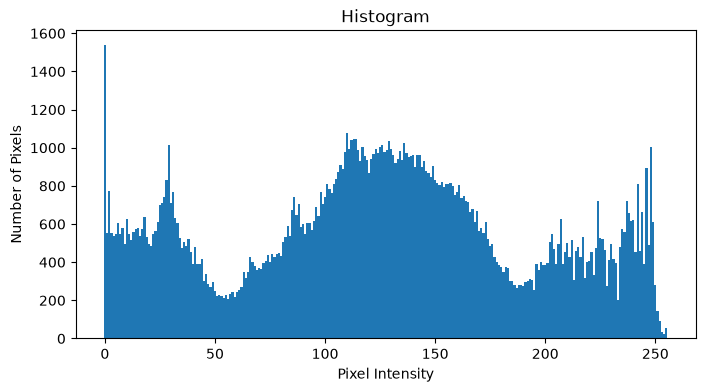

In [30]:
plt.figure(figsize=(8,4))
plt.bar(range(256),histogram, width=1)
plt.title("Histogram")
plt.xlabel("Pixel Intensity")
plt.ylabel("Number of Pixels")
plt.show()

In [31]:
print("MAX common intensity value:", np.argmax(histogram))
print("Number of pixels at that intensity:", histogram.max())

MAX common intensity value: 0
Number of pixels at that intensity: 1538


In [37]:
plt.figure(figsize=(8,4))
plt.plot(histogram_cv2)
plt.title("Histogram (cv2.calcHist)")
plt.xlabel("Pixel Intensity")
plt.ylabel("Number of Pixels")
plt.show()

NameError: name 'histogram_cv2' is not defined

<Figure size 800x400 with 0 Axes>

In [33]:
cdf = histogram.cumsum()
cdf_normalized = cdf * 255 / cdf[-1]

In [34]:
equalized_manual = np.interp(img.flatten(), np.arange(256), cdf_normalized)
equalized_manual = equalized_manual.reshape(img.shape)
equalized_manual = equalized_manual.astype(np.uint8)

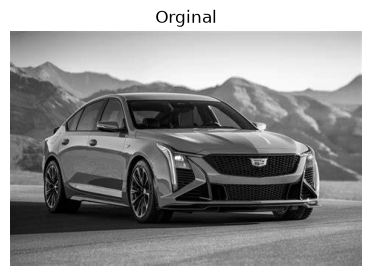

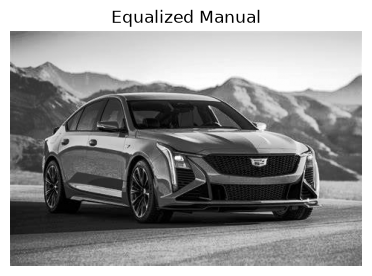

In [40]:
plt.figure(figsize=(10,5))
plt.subplot(1,2,1)
plt.title("Orginal")
plt.imshow(img, cmap = "gray")
plt.axis("off")
plt.show()

plt.figure(figsize=(10,5))
plt.subplot(1,2,2)
plt.title("Equalized Manual")
plt.imshow(equalized_manual, cmap = "gray")
plt.axis("off")
plt.show()

In [44]:
equalized_cv2 = cv2.equalizeHist(img)

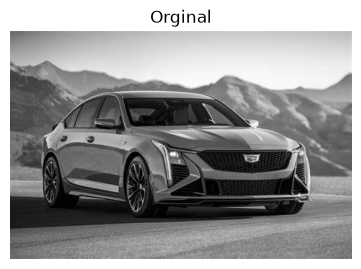

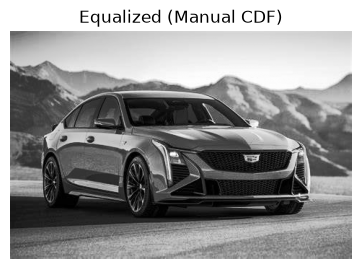

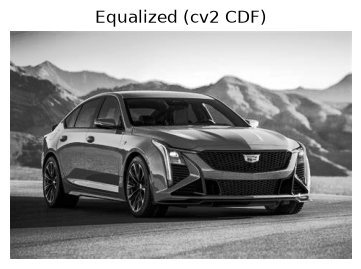

In [46]:
plt.figure(figsize=(15,4))
plt.subplot(1,3,1)
plt.title("Orginal")
plt.imshow(img, cmap = "gray")
plt.axis("off")
plt.show()

plt.figure(figsize=(15,4))
plt.subplot(1,3,1)
plt.title("Equalized (Manual CDF)")
plt.imshow(equalized_manual, cmap = "gray")
plt.axis("off")
plt.show()

plt.figure(figsize=(15,4))
plt.subplot(1,3,1)
plt.title("Equalized (cv2 CDF)")
plt.imshow(equalized_cv2, cmap = "gray")
plt.axis("off")
plt.show()

In [48]:
hist_manual_eq, _ = np.histogram(equalized_manual.flatten(), bins=256, range=(0,256))
hist_cv2_eq, _ = np.histogram(equalized_cv2.flatten(), bins=256, range=(0,256))

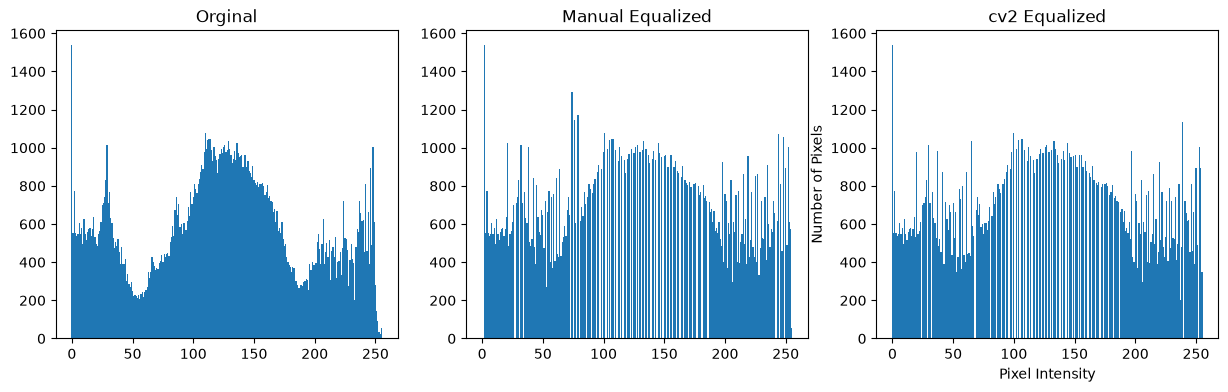

In [49]:
plt.figure(figsize=(15,4))

plt.subplot(1,3,1)
plt.bar(range(256),histogram, width=1)
plt.title("Orginal")

plt.subplot(1,3,2)
plt.bar(range(256),hist_manual_eq, width=1)
plt.title("Manual Equalized")

plt.subplot(1,3,3)
plt.bar(range(256),hist_cv2_eq, width=1)
plt.title("cv2 Equalized")

plt.xlabel("Pixel Intensity")
plt.ylabel("Number of Pixels")
plt.show()